## In this project, I am modeling active inference agent behavior via a TMaze environment. 

Name: Aradhana (Ara) Anandkumar 

Special thanks to all the instructors of the Active Inference Institute. Thank you for the wonderful lectures, textbook readings, and symposiums this year. 

*Note: This implementation was made possible through the [official pymdp documentation site](https://pymdp-rtd.readthedocs.io/en/latest/)*

- *TMaze Demo Documentation: https://pymdp-rtd.readthedocs.io/en/latest/tutorials/notebooks/examples/envs/tmaze_demo/* 


### I want to model the following interests: 

 - How likely is an agent (or a series of agents) is to follow the cue to the reward side with a certain confidence threshold (e.g. confidence = 0.9)?
 - How likely is an agent (or series of agents) is to recover from initial shock and end up in the reward loc? At what point in the timestep did the agent's q/s (belief about the hidden state) go beyond 0.9 after encountering initial shock? And, how did the change in belief guide the agent to the correct reward side? 

### Research Questions: 
1. Does confidence hinder or encourage agents to seek information?
2. Is an agent of higher confidence more likely to disregard reliable cues, even at the risk of encountering an unpreferred outcome?
3. In situations of higher agent confidence, is the epistemic term made negligible, making it so that the agent is dictated primarily by its pragmatic terms?  

#### I predict the following: 
-  Higher confidence in agents reduce information-seeking behaviors (epistemic value), and increases action impulsivity (pragmatic value). If confidence is high, agents are more likely to act by it; whereas, if confidence is low, agents are likely to seek information *prior* to acting.
- An overly confident agent (regardless if their confidence is correct) is more likely to disregard reliable cue observations and encounter shock as opposed to an uncertain agent. 

### My intention: 
I aim to understand the difference between RL models (mandated by epislon-greedy, or undirected exploratory tendencies) and active inference models. 

For this project, I will not be constructing a separate RL model to illustrate the differences; however, I will be portraying the dynamic attributes of an active inference model against undirected exploration predictions. 

Active Inference 


In [1]:
import numpy as np
import jax.numpy as jnp 
import json # for results readability 
from jax import random as jrand
import matplotlib.pyplot as plt 
from pymdp.envs import TMaze, rollout # intiializes environment (generative process) 
from pymdp.agent import Agent # initializes agent (generative model) 
import ipywidgets as wig

In [2]:
# toy-pymdp active-inference model with one agent (for insight) 

# setting up the generative process 
envr_ag1 = TMaze(
    reward_probability = 1.0, 
    punishment_probability = 1.0, 
    cue_validity = 1.0, 
    reward_condition = None, 
    dependent_outcomes = False,
    # categorical_obs = False   
) 

# setting up the generative model of the agent 
A = envr_ag1.A 
A_dependencies = envr_ag1.A_dependencies

B = envr_ag1.B
B_dependencies = envr_ag1.B_dependencies

C = [jnp.zeros(x.shape[0], dtype=jnp.float32) for x in A] # setting up neutral preferences for the agent 
C[1] = C[1].at[1].set(+2.0) # outcome channels are observational: outcome -> reward outcome + ranking of the outcome 
C[1] = C[1].at[2].set(-3.0) # if the agent arrives at the cheese, it likes it, but when arrives at nothing, it dislikes it 

d_location = jnp.zeros(B[0].shape[0], dtype=jnp.float32).at[0].set(1.0) # the agent starts in the center of the T-maze
d_reward = jnp.array([0.5, 0.5], dtype=jnp.float32)
D = [d_location, d_reward] # both location and reward are hidden states  

In [3]:

# intiializing agent 1 
ac_infer_agent = Agent(
    A, B, C, D, 
    policy_len = 2, 
    A_dependencies = A_dependencies, 
    B_dependencies = B_dependencies, 
    batch_size = 1, # only one agent
    learn_A = False, 
    learn_B = False, 
    
)

model_key = jrand.PRNGKey(0) # randomness is reporducible; sets a constant seed

# info_diary shows: what the agent observed, how it acted, and what it believed (relative to prior beliefs)
# info diary = frames of timesteps 

final_state, info_diary = rollout( # final state doesn't need to be printed; shows the end state of the model 
    ac_infer_agent, 
    envr_ag1, num_timesteps=4, # 4 * perceiving, planning, and acting; 4 rounds 
    rng_key = model_key)

for i in ["observation", "action", "qs"]: #qs = model's belief about hidden states AFTER observing a hidden state
    # qs; belief influences behavior 
    print(i, [np.array(y).shape for y in info_diary[i]]) # shape of each array  


observation [(1, 5, 1), (1, 5, 1), (1, 5, 1)]
action [(5, 2)]
qs [(1, 5, 5), (1, 5, 2)]


In [4]:
location_ns = ["center", "left_arm", "right_arm", "at_cue", "in_between"]
out_ns = ["nothing", "reward", "shock"]
cue_ns = ["no cue", "left_cue", "right_cue"]


observations = [np.array(o).squeeze() for o in info_diary["observation"]]
# location, cue, and reward outcome 

model_list = [] 
for f in range(len(observations[0])):
    model_loc = location_ns[int(observations[0][f])]# frame f of the location channel
    model_outcome = out_ns[int(observations[1][f])] # reward outcome at frame f 
    model_cue = cue_ns[int(observations[2][f])]

    model_list.append([model_loc, model_outcome, model_cue])

for z, frame in enumerate(model_list, start = 1):
    print(str(f"{z}."), frame) 

# 

1. ['center', 'nothing', 'no cue']
2. ['at_cue', 'nothing', 'left_cue']
3. ['center', 'nothing', 'no cue']
4. ['in_between', 'nothing', 'no cue']
5. ['left_arm', 'reward', 'no cue']


In [5]:
# making reproducible results 
# note_1: reward_side is 1; hidden reward side is set to right; 0 = left, 1 = right
def activ_infer_agent_run(confidence, reward_side = 1, reward_lkl=1.0, num_agents=100, agent_shock=-3.0, num_timesteps=16, seed=0):
    
    experimental_envr = TMaze(
        reward_probability=reward_lkl, 
        punishment_probability=1.0, # agent_shock is how much the agent dislikes unpreferred outcome; punishment = likelihood of shock
        cue_validity= 1.0, 
        reward_condition = reward_side,  
        dependent_outcomes = False
    
 )

    # new generative model for exper_agent
    A = [jnp.broadcast_to(a, (num_agents,) + a.shape) for a in experimental_envr.A] 
    B = [jnp.broadcast_to(b, (num_agents,) + b.shape) for b in experimental_envr.B]
    
    C = [jnp.zeros((num_agents, a.shape[1]), dtype = jnp.float32) for a in A]
    C[1] = C[1].at[:, 1].set(+2.0) # A[1][1] - nothing, reward (x), shock
    C[1] = C[1].at[:, 2].set(agent_shock) # A[1][2] - nothing, reward, shock (x) 
    
    exp_d_locations = jnp.zeros(experimental_envr.B[0].shape[0], dtype=jnp.float32).at[0].set(1.0) # agents start at the center 

    # for confidence neutrality 
    if reward_side == 0: # reward on left
        exp_d_rewards = jnp.array([confidence, 1-confidence], dtype=jnp.float32)
    else: # reward on right 
        exp_d_rewards = jnp.array([1 - confidence, confidence], dtype=jnp.float32)
        
    
    D = [jnp.broadcast_to(d, (num_agents,) + d.shape) for d in [exp_d_locations, exp_d_rewards]]

    exper_agent = Agent(
        A, B, C, D,
        A_dependencies = experimental_envr.A_dependencies, 
        B_dependencies = experimental_envr.B_dependencies, 
        batch_size = num_agents, # this will be 100
        policy_len = 2, 
        action_selection = "stochastic", 
        learn_A = False, 
        learn_B = False 
    
    )
    
    final_state, info_diary = rollout(
        exper_agent, 
        experimental_envr, 
        num_timesteps=num_timesteps, 
        rng_key=jrand.PRNGKey(seed)
    )
    
    # note_2: down the rows, across the columns 
    agent_location = np.array(info_diary["observation"][0])[:, :, 0] 
    agent_outcome = np.array(info_diary["observation"][1])[:, :, 0]
    
    return agent_location, agent_outcome 
        

In [6]:
def classify_agent_behavior(agent_loc, agent_out):
    arms_loc = np.where((agent_loc == 1) | (agent_loc == 2))[0]
    if not arms_loc.any(): 
        return "never reached an arm side (left/right)"
    x = arms_loc[0] # first encountered reward side: either 1 (reward) or 2 (shock) 
    cues_visited_prior = (agent_loc[:x] == 3).any()
    if cues_visited_prior and agent_out[x] == 1: 
        return "read CUE -> reached REWARD" 
    elif cues_visited_prior and agent_out[x] == 2: 
        return "read CUE -> reached SHOCK" 
    elif agent_out[x] == 1: 
        return "skipped CUE -> reached REWARD"
    elif (agent_out[x:] == 1).any(): # encountering reward after initial reward/shcok frame indicates recovery 
        return "skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD"
    else: # basically agent_out[x:] == 2 
        return "skipped CUE -> reached SHOCK -> STUCK and never recovered" 

    


In [7]:
agent_confidences = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
REWARD_SIDE = 0 # can be tweaked 

agent_read_cue = [] # agent read the cue 
agent_skp_cue_rew = [] # agent skipped the cue, and then reached reward 
agent_encr_shock_recov = [] # agent reached shock, then recovered; regardless of cue read 

for ac in agent_confidences: 
    location, outcome = activ_infer_agent_run(ac, reward_side=REWARD_SIDE) # 0 = LEFT 

    final_paths = [] 
    counting_paths = {} 
    
    for i in range(len(location)): 
        final_paths.append(classify_agent_behavior(location[i], outcome[i]))
   
    for p in final_paths: 
        if p in counting_paths:
            counting_paths[p]+=1
        else: 
            counting_paths[p] = 1 
    path_labels = [
        "read CUE -> reached REWARD",
        "read CUE -> reached SHOCK",
        "skipped CUE -> reached REWARD",
        "skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD",
        "skipped CUE -> reached SHOCK -> STUCK and never recovered"
    ]
    print(f"CONFIDENCE LEVEL: {ac}, REWARD_SIDE: {REWARD_SIDE} ")
    for p_l in path_labels: 
        print(f"{counting_paths.get(p_l, 0)} {p_l}")
        
    print() 


    # fraction of the 100 agents; each path/len(location) 

    agent_read_cue.append(
        (counting_paths.get("read CUE -> reached REWARD", 0) + counting_paths.get("read CUE -> reached SHOCK", 0))/len(location)
    )

    agent_skp_cue_rew.append(
        (counting_paths.get("skipped CUE -> reached REWARD", 0))/len(location) 
    )

    agent_encr_shock_recov.append(
        (counting_paths.get("skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD", 0))/len(location) 
    )

CONFIDENCE LEVEL: 0.0, REWARD_SIDE: 0 
19 read CUE -> reached REWARD
1 read CUE -> reached SHOCK
0 skipped CUE -> reached REWARD
68 skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD
4 skipped CUE -> reached SHOCK -> STUCK and never recovered

CONFIDENCE LEVEL: 0.1, REWARD_SIDE: 0 
37 read CUE -> reached REWARD
0 read CUE -> reached SHOCK
1 skipped CUE -> reached REWARD
49 skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD
1 skipped CUE -> reached SHOCK -> STUCK and never recovered

CONFIDENCE LEVEL: 0.2, REWARD_SIDE: 0 
49 read CUE -> reached REWARD
0 read CUE -> reached SHOCK
1 skipped CUE -> reached REWARD
34 skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD
1 skipped CUE -> reached SHOCK -> STUCK and never recovered

CONFIDENCE LEVEL: 0.3, REWARD_SIDE: 0 
59 read CUE -> reached REWARD
0 read CUE -> reached SHOCK
0 skipped CUE -> reached REWARD
24 skipped CUE -> reached SHOCK -> RECOVERED and reached REWARD
1 skipped CUE -> reached SHOCK -> STUCK and n

In [8]:
print(len(agent_confidences), len(agent_read_cue), len(agent_skp_cue_rew), len(agent_encr_shock_recov))

11 11 11 11


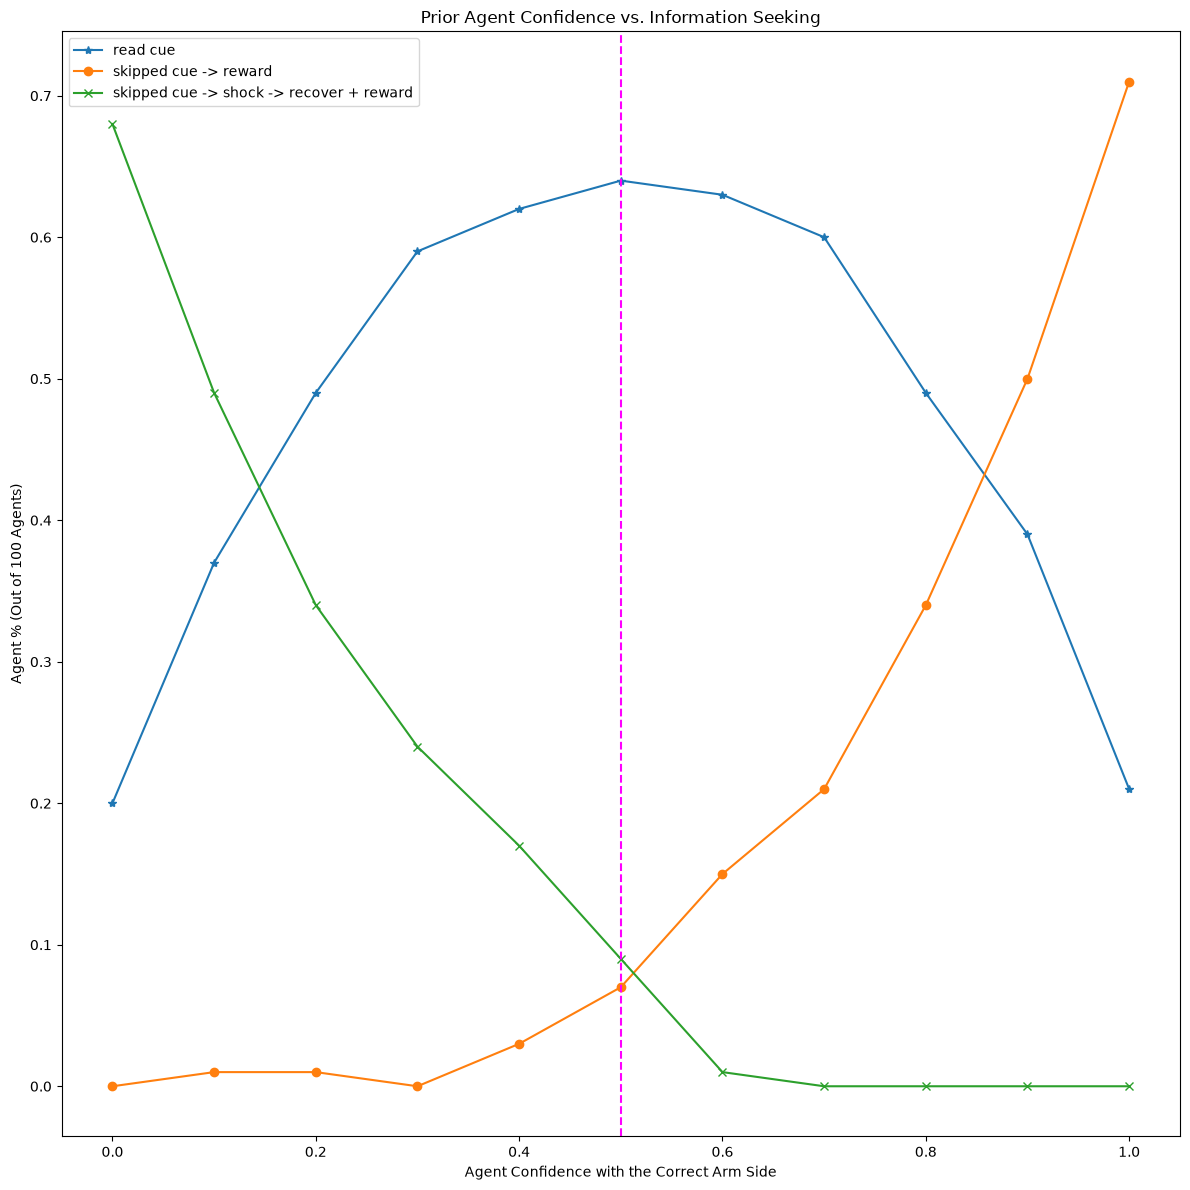

In [9]:
plt.figure(figsize=(12, 12))
plt.plot(agent_confidences, agent_read_cue, marker="*", label="read cue")
plt.plot(agent_confidences, agent_skp_cue_rew, marker="o", label="skipped cue -> reward")
plt.plot(agent_confidences, agent_encr_shock_recov, marker="x", label="skipped cue -> shock -> recover + reward")

plt.axvline(0.5, linestyle="--", color="magenta")
plt.ylabel("Agent % (Out of 100 Agents)")
plt.xlabel("Agent Confidence with the Correct Arm Side")

plt.title("Prior Agent Confidence vs. Information Seeking") 
plt.legend()
plt.tight_layout() 

plt.savefig("agent_behavior_information_seeking.png", dpi=150)
plt.show() 


### Final Observations: 
- Agents tend to read the cue with a 0.5 confidence, regardless of which arm that confidence is towards.
- Agents with **higher AND correct** confidence tend to skip the cue, and reach the reward; hence, reinforcing my predictions that higher confidence (given that it is targeted towards the reward side) encourages the agent to act towards its preferred outcome instead of seeking more information.
- BUT, agents with **lower** confidence also tended to skip the cue, but first encountered shock by turning towards the incorrect reward side, before it corrected its mistake, and reached the reward side.

Therefore, my findings are: 
1. Higher confidence (regardless whether it is of the correct/incorrect arm side of the T-Maze) encourages agents to act first without seeking infromation. So, two agents of confidence 0.0 and 0.9 respectively will exhibit higher pragmatic behavior (tendency to act first) and lower epistemic behavior (tendency to seek information).
2. Agents with a confidence of 0.5 are often the ones to read the cue, update beliefs about the hidden state, and act accordingly to reach its preferred outcome. 